# 02 · Data Preparation and Feature Engineering

We turn the raw sensor data into a clean table that the models can learn from.

**Steps:**
1. Create the **RUL target** (and cap it at 125)
2. Remove useless sensors
3. Split into **training** and **validation** engines
4. Build **engineered features** (moving average, std, trend slope, deviation)
5. Check for **data leakage**
6. Save everything for the model notebooks (03 – 06)

> 💡 Cells marked with **⋯** are hidden because they only contain plotting or helper code. Click them to expand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from utils import savefig, RUL_CAP, WINDOW, SEED

# The NASA files are plain text: values separated by spaces, no header row.
# So we tell pandas the separator (sep=r"\s+" = one or more spaces) and give the 26 column names ourselves.
columns = ["unit", "cycle", "setting_1", "setting_2", "setting_3"] + [f"s{i}" for i in range(1, 22)]

train = pd.read_csv("../data/raw/train_FD001.txt", sep=r"\s+", header=None, names=columns)
test = pd.read_csv("../data/raw/test_FD001.txt", sep=r"\s+", header=None, names=columns)

# The answer key: true RUL of each test engine, one number per line (line 1 = engine 1, ...)
test_true_rul = pd.read_csv("../data/raw/RUL_FD001.txt", header=None, names=["RUL_raw"])
test_true_rul["unit"] = range(1, 101)

## 1. RUL target
For every row: **RUL = last cycle of that engine − current cycle.**
*Example:* an engine fails at cycle 200 → at cycle 150 its RUL is 50.

**Why cap at 125?** Early in life every engine looks healthy, so nobody (not even a model) can tell
"300 cycles left" from "150 cycles left". So we say **"healthy = 125"** and only count down after that.

In [2]:
train["RUL_raw"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
train["RUL"] = train["RUL_raw"].clip(upper=RUL_CAP)

train.loc[train["unit"] == 1, ["unit", "cycle", "RUL_raw", "RUL"]].iloc[[0, 1, 2, 100, 150, -1]]

,unit,cycle,RUL_raw,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
100,1,101,91,91
150,1,151,41,41
191,1,192,0,0


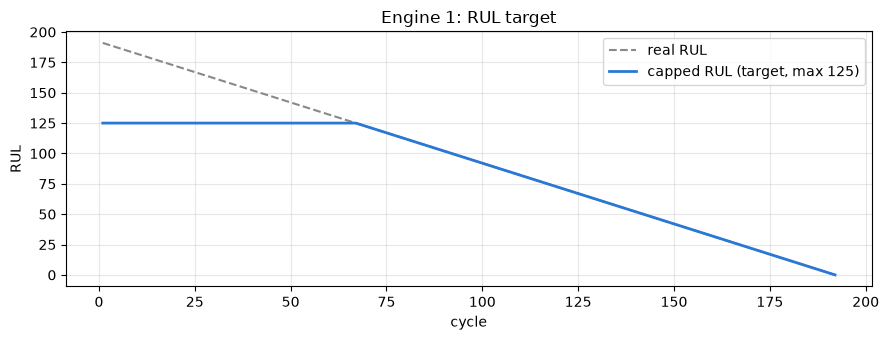

In [3]:
d = train[train["unit"] == 1]
plt.figure(figsize=(9, 3.5))
plt.plot(d["cycle"], d["RUL_raw"], "--", color="#8a8984", label="real RUL")
plt.plot(d["cycle"], d["RUL"], color="#2a78d6", lw=2, label=f"capped RUL (target, max {RUL_CAP})")
plt.title("Engine 1: RUL target"); plt.xlabel("cycle"); plt.ylabel("RUL"); plt.legend()
savefig("02_rul_target")

## 2. Remove useless sensors
From the EDA: 7 sensors never change and the 3 operating settings are constant → we keep **14 sensors**.

In [4]:
SENSORS = [s for s in [f"s{i}" for i in range(1, 22)] if train[s].nunique() > 2]
print(len(SENSORS), "sensors kept:", SENSORS)

14 sensors kept: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 3. Split by engine (not by row!)
**80 engines → training**, **20 engines → validation**.

⚠️ Rows from the same engine look almost the same. If we split rows randomly, the model would see part of a
validation engine during training and the score would be too optimistic. Splitting **by engine** is fair.

In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(splitter.split(train, groups=train["unit"]))
val_units = train.iloc[val_idx]["unit"].unique()
train["split"] = np.where(train["unit"].isin(val_units), "val", "train")

print(train.groupby("split")["unit"].nunique())
print("Validation engines:", sorted(val_units))

split
train    80
val      20
Name: unit, dtype: int64
Validation engines: [np.int64(1), np.int64(5), np.int64(11), np.int64(13), np.int64(19), np.int64(23), np.int64(31), np.int64(32), np.int64(34), np.int64(40), np.int64(45), np.int64(46), np.int64(54), np.int64(71), np.int64(74), np.int64(77), np.int64(78), np.int64(81), np.int64(84), np.int64(91)]


## 4. Feature engineering
For every sensor we create 4 new features, using only the **last 10 cycles of the same engine** (never the future):

| Feature | Meaning | Why it helps |
|---|---|---|
| `s11_mean` | **moving average** of the last 10 readings | removes noise |
| `s11_std` | spread of the last 10 readings | shows if the sensor becomes unstable |
| `s11_slope` | slope of a straight line (OLS) through the last 10 readings | shows the **trend** — rising or falling, and how fast |
| `s11_dev` | rolling mean − the engine's own healthy start value (first 10 cycles) | how far the engine drifted from **its own** healthy state |

We also keep `cycle` (engine age) and the 14 raw sensors → **1 + 14 + 14 × 4 = 71 features**.

*(The code is hidden because it is long — click to expand. It loops over engines one by one so engines never mix.)*

In [6]:
def make_features(df):
    all_engines = []
    for unit, g in df.groupby("unit"):              # each engine separately -> no mixing of engines
        g = g.sort_values("cycle").copy()
        t = g["cycle"]
        for s in SENSORS:
            roll = g[s].rolling(WINDOW, min_periods=1)
            g[f"{s}_mean"] = roll.mean()
            g[f"{s}_std"] = roll.std().fillna(0)
            slope = g[s].rolling(WINDOW, min_periods=2).cov(t) / t.rolling(WINDOW, min_periods=2).var()
            g[f"{s}_slope"] = slope.fillna(0)
            baseline = g[s].expanding().mean().where(t <= 10).ffill()   # mean of first 10 cycles (past only)
            g[f"{s}_dev"] = g[f"{s}_mean"] - baseline
        all_engines.append(g)
    return pd.concat(all_engines, ignore_index=True)

In [7]:
FEATURES = ["cycle"] + SENSORS + [f"{s}_{k}" for s in SENSORS for k in ["mean", "std", "slope", "dev"]]

train_feat = make_features(train)

# Test set: build features from each test engine's own history, keep only its LAST cycle (= the moment we predict)
test_feat = make_features(test).groupby("unit").tail(1).merge(test_true_rul, on="unit")
test_feat["RUL"] = test_feat["RUL_raw"].clip(upper=RUL_CAP)

print("Number of features:", len(FEATURES))
print("Train rows:", len(train_feat), "| Test engines:", len(test_feat))
train_feat[["unit", "cycle", "s11", "s11_mean", "s11_std", "s11_slope", "s11_dev", "RUL"]].head(12)

Number of features: 71
Train rows: 20631 | Test engines: 100


,unit,cycle,s11,s11_mean,s11_std,s11_slope,s11_dev,RUL
0,1,1,47.47,47.470000,0.000000,0.000000,0.000,125
1,1,2,47.49,47.480000,0.014142,0.020000,0.000,125
2,1,3,47.27,47.410000,0.121655,-0.100000,0.000,125
3,1,4,47.13,47.340000,0.171659,-0.124000,0.000,125
4,1,5,47.28,47.328000,0.151063,-0.074000,0.000,125
5,1,6,47.16,47.300000,0.151526,-0.066286,0.000,125
6,1,7,47.36,47.308571,0.140170,-0.035000,0.000,125
7,1,8,47.24,47.300000,0.132017,-0.029048,0.000,125
8,1,9,47.29,47.298889,0.123536,-0.021000,0.000,125
9,1,10,47.03,47.272000,0.144207,-0.029939,0.000,125


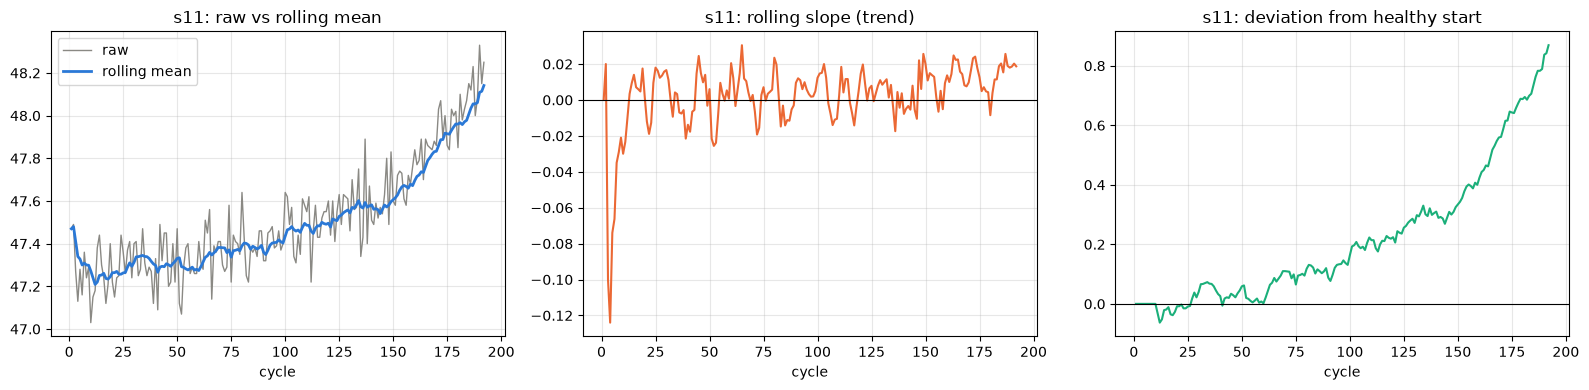

In [8]:
d = train_feat[train_feat["unit"] == 1]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(d["cycle"], d["s11"], color="#8a8984", lw=1, label="raw")
ax[0].plot(d["cycle"], d["s11_mean"], color="#2a78d6", lw=2, label="rolling mean")
ax[0].set(title="s11: raw vs rolling mean", xlabel="cycle"); ax[0].legend()
ax[1].plot(d["cycle"], d["s11_slope"], color="#eb6834"); ax[1].axhline(0, color="black", lw=0.8)
ax[1].set(title="s11: rolling slope (trend)", xlabel="cycle")
ax[2].plot(d["cycle"], d["s11_dev"], color="#1baf7a"); ax[2].axhline(0, color="black", lw=0.8)
ax[2].set(title="s11: deviation from healthy start", xlabel="cycle")
savefig("02_features_example")

**Observation (engine 1, sensor s11):** the rolling mean removes the noise. Slope and deviation stay near **0 while the
engine is healthy** and **rise near the end of its life** — exactly the signal we want the models to learn.

## 5. Data leakage checks
Automatic checks (hidden — click to expand):
1. Features **never use future cycles** (recompute engine 1 with only its first 100 cycles → must give the same values)
2. No missing values, and the target `RUL` is **not** a feature
3. Training and validation engines **do not overlap**

In [9]:
short = make_features(train[(train["unit"] == 1) & (train["cycle"] <= 100)])
full = train_feat[train_feat["unit"] == 1].head(100)
assert np.allclose(short[FEATURES].values, full[FEATURES].values), "features use future data!"
assert train_feat[FEATURES].isna().sum().sum() == 0 and test_feat[FEATURES].isna().sum().sum() == 0
assert "RUL" not in FEATURES and "RUL_raw" not in FEATURES
tr_units = set(train_feat.loc[train_feat["split"] == "train", "unit"])
va_units = set(train_feat.loc[train_feat["split"] == "val", "unit"])
assert tr_units.isdisjoint(va_units)
print("✅ All leakage checks passed")

✅ All leakage checks passed


## 6. Save for the model notebooks

In [10]:
train_feat.to_csv("../data/processed/train_features.csv", index=False)
test_feat.to_csv("../data/processed/test_features.csv", index=False)
with open("../data/processed/feature_list.txt", "w") as f:   # the 71 feature names, one per line
    f.write("\n".join(FEATURES))
print("Saved to data/processed/")

Saved to data/processed/


## ✅ Summary
* Target: **RUL capped at 125**.
* **14 sensors** kept, **71 features** built, all from past data of the same engine.
* **80 training / 20 validation engines**, plus the **100 official test engines** (last cycle only).
* Next: train the models → **03 Linear Regression**, **04 Decision Tree**, **05 Random Forest**.